**objective:** Perform end-to-end EDA on a UK-based online retailer's transaction data to identify sales trends, top performing products, and revenue distribution across markets.
**Dataset:** 541,909 transactions (Dec 2010 - Dec 2011) | **Tools:** Python, Pandas, Matplotlib

In [1]:
import pandas as pd
df = pd.read_csv('data.csv', encoding = 'ISO-8859-1')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [3]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [4]:
df[df['Quantity']<0].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/2010 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/2010 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom


In [5]:
df_clean = df[df['Quantity'] > 0 ]

In [6]:
df_clean = df_clean.dropna(subset=['CustomerID'])

In [7]:
df_clean = df_clean.drop_duplicates()

In [8]:
print(f"Original rows: {len(df)}")

Original rows: 541909


In [9]:
print(f"Cleaned rows: {len(df_clean)}")

Cleaned rows: 392732


In [10]:
print(f"Rows removed: {len(df) - len(df_clean)}")

Rows removed: 149177


In [11]:
df_clean['TotalPrice'] = df_clean['Quantity'] * df_clean['UnitPrice']
df_clean[['Quantity', 'UnitPrice', 'TotalPrice']].head()

,Quantity,UnitPrice,TotalPrice
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [12]:
import matplotlib.pyplot as plt

top_products = df_clean.groupby('Description')['TotalPrice'].sum().sort_values(ascending=False).head(10)
print(top_products)

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          56413.03
Manual                                 53419.93
RABBIT NIGHT LIGHT                     51251.24
Name: TotalPrice, dtype: float64


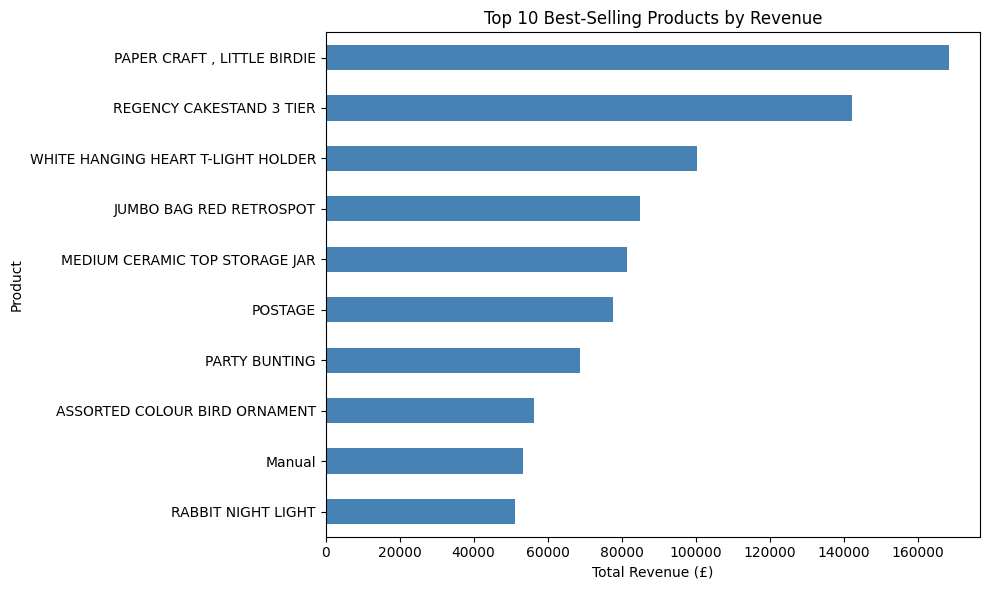

In [13]:
plt.figure(figsize=(10,6))
top_products.sort_values().plot(kind='barh', color='steelblue')
plt.xlabel('Total Revenue (£)')
plt.ylabel('Product')
plt.title('Top 10 Best-Selling Products by Revenue')
plt.tight_layout()
plt.show()


In [14]:
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])
df_clean['Month'] = df_clean['InvoiceDate'].dt.to_period('M')

monthly_sales = df_clean.groupby('Month')['TotalPrice'].sum()
print(monthly_sales)

Month
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517190.440
Freq: M, Name: TotalPrice, dtype: float64


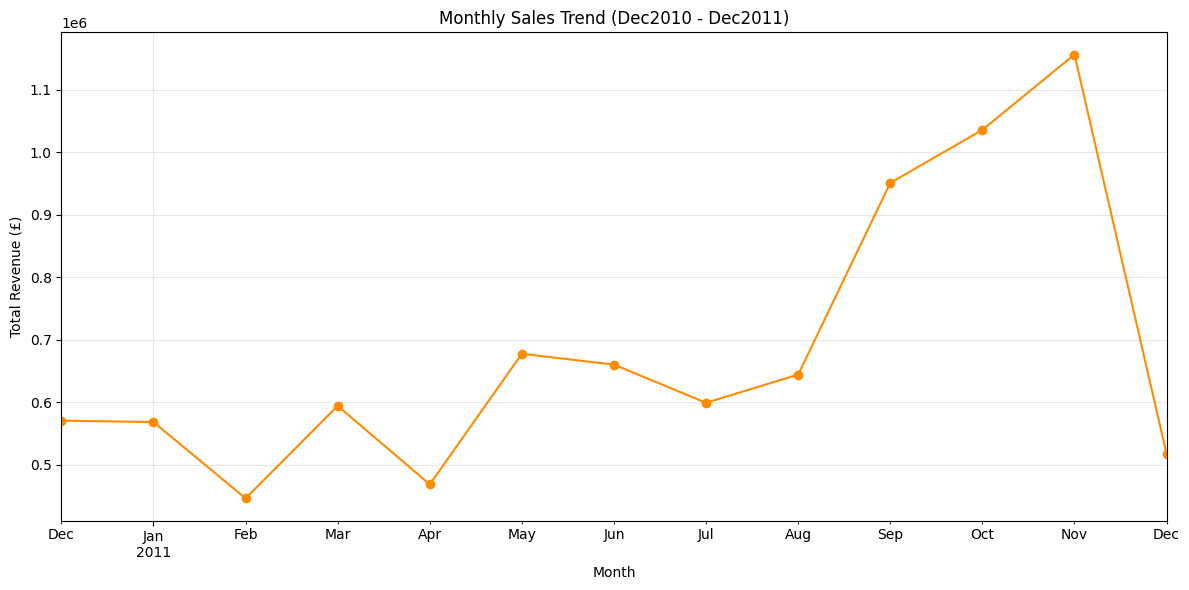

In [15]:
plt.figure(figsize=(12,6))
monthly_sales.plot(kind='line', marker='o', color='darkorange')
plt.xlabel('Month')
plt.ylabel('Total Revenue (£)')
plt.title('Monthly Sales Trend (Dec2010 - Dec2011)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

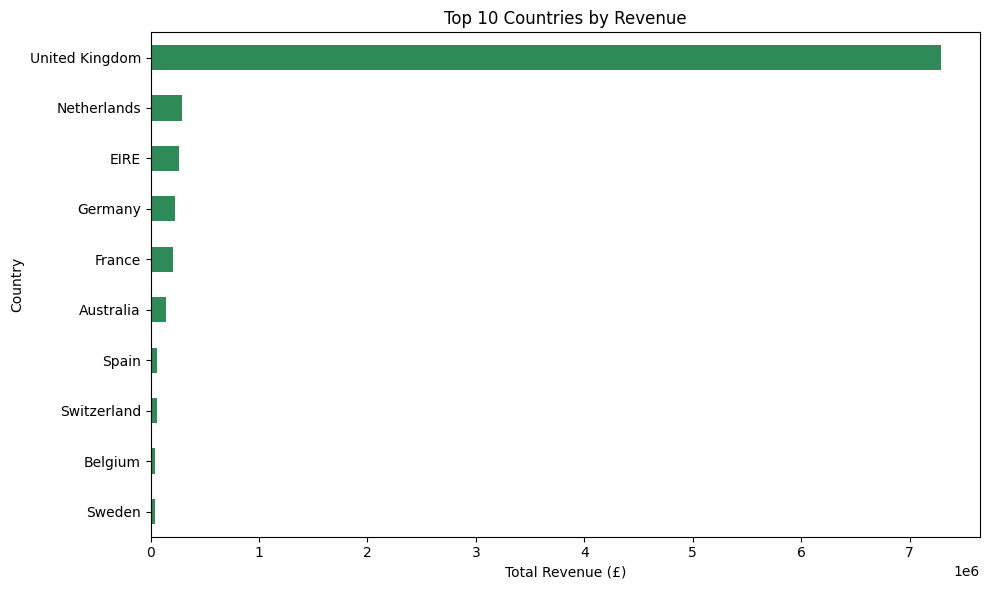

In [16]:
top_countries = df_clean.groupby('Country')['TotalPrice'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,6))
top_countries.sort_values().plot(kind='barh', color='seagreen')
plt.xlabel('Total Revenue (£)')
plt.ylabel('Country')
plt.title('Top 10 Countries by Revenue')
plt.tight_layout()
plt.show()

In [17]:
total_revenue = df_clean['TotalPrice'].sum()
uk_revenue = df_clean[df_clean['Country'] == 'United Kingdom'] ['TotalPrice'].sum()
uk_percentage = (uk_revenue / total_revenue) * 100

print(f"Total Revenue: £{total_revenue: ,.2f}")
print(f"UK Revenue: £{uk_revenue: ,.2f}")
print(f"UK % of Total: {uk_percentage: ,.2f}%")

Total Revenue: £ 8,887,208.89
UK Revenue: £ 7,285,024.64
UK % of Total:  81.97%


## Key Findings

**1. Data Quality:** The raw dataset contained 541,909 transactions, of which ~25% had missing Customer IDs and ~10,000 were cancelled orders (negative quantities). After cleaning, 392,732 valid transaction records remained for analysis.

**2. Top Products:** "Paper Craft, Little Birdie" was the top revenue-generating product (£168,469.60), followed by the Regency Cakestand 3 Tier (£142,264.75).

**3. Seasonal Trend:** Revenue grew steadily through the year, peaking in November 2011 (£1.16M) — consistent with pre-holiday shopping demand. The December drop reflects an incomplete month of data rather than an actual decline.

**4. Market Concentration:** The UK accounted for 81.97% of total revenue (£7.29M of £8.89M), despite the business serving 38 countries — indicating a heavily domestic customer base with limited international penetration.

## Recommendations

- Focus marketing spend around the Sep–Nov period to capitalize on the pre-holiday demand surge
- Investigate low international revenue share — targeted campaigns in high-potential secondary markets (Netherlands, Germany) could diversify revenue
- Prioritize inventory planning around top-selling SKUs identified in this analysis